# Connected-Cluster Formal-Log Benchmark

This notebook only reads benchmark data from `scripts/data/hncc_cluster_log_data.json`. Generate the data first with `python scripts/hncc_cluster_log_collect.py`.

In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['text.usetex'] = True
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "scripts").exists() and (ROOT.parent / "scripts").exists():
    ROOT = ROOT.parent
DATA_PATH = Path(os.environ.get("HNCC_CLUSTER_LOG_DATA", ROOT / "scripts" / "data" / "hncc_cluster_log_data.json"))
FIGURE_TAG = os.environ.get("HNCC_FIGURE_TAG", "")
FIGURE_DIR = ROOT / "figures"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing {DATA_PATH}. Run: python scripts/hncc_cluster_log_collect.py")

with DATA_PATH.open("r", encoding="utf-8") as f:
    payload = json.load(f)

cases = payload["cases"]
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
payload["metadata"]

{'n_values': [10], 'order': 2, 'qmax': [5, 6]}

Saved /Users/AntiEntropy/Documents/Research/Overleaf/NCC with log precision/figures/hncc_cluster_log_timing_N10.pdf


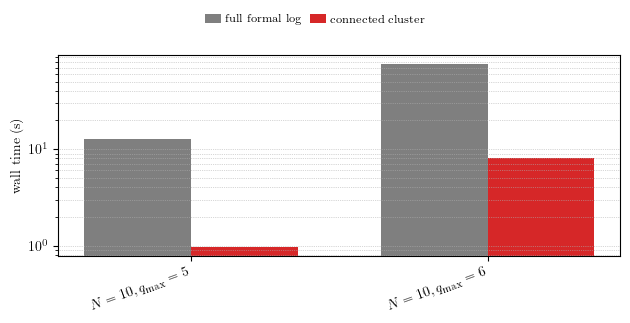

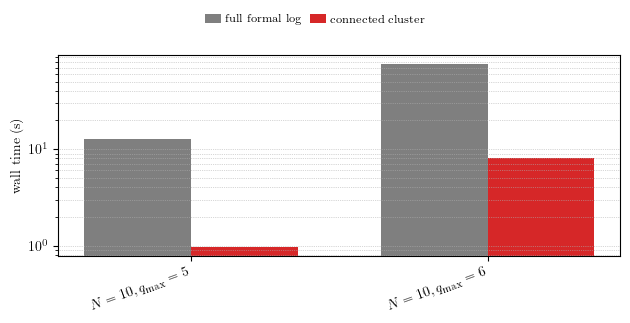

In [2]:
labels = [fr"$N={case['N']}, q_{{\max}}={case['qmax']}$" for case in cases]
x = np.arange(len(cases))
width = 0.36

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar(x - width / 2, [case["full_time"] for case in cases], width, label="full formal log", color="#7f7f7f")
ax.bar(x + width / 2, [case["cluster_time"] for case in cases], width, label="connected cluster", color="#d62728")
ax.set_yscale("log")
ax.set_ylabel("wall time (s)")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.grid(True, axis="y", which="both", ls=":", lw=0.5)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=2, fontsize=8.5, frameon=False, handlelength=1.35, handletextpad=0.35, columnspacing=0.7, borderaxespad=0.0)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.90))

path = FIGURE_DIR / f"hncc_cluster_log_timing{FIGURE_TAG}.pdf"
fig.savefig(path)
print(f"Saved {path}")
fig

Saved /Users/AntiEntropy/Documents/Research/Overleaf/NCC with log precision/figures/hncc_cluster_log_diff_norm_N10.pdf


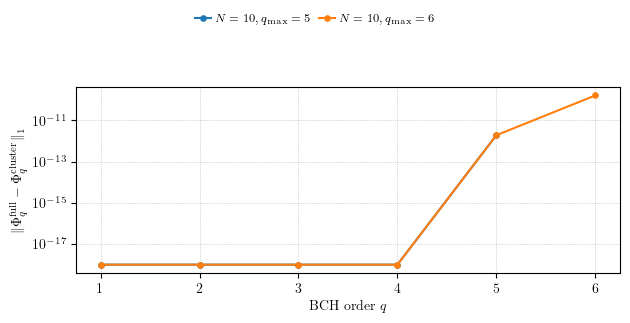

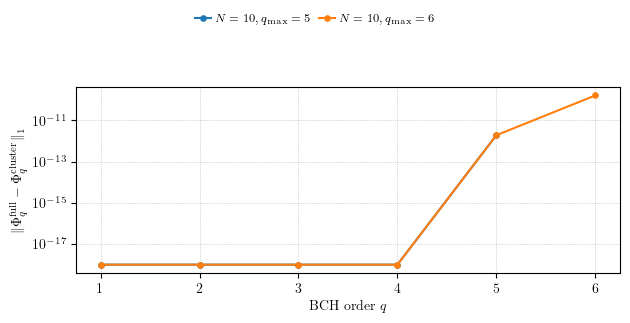

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for case in cases:
    q = np.array([row["q"] for row in case["orders"]])
    diff = np.array([max(row["diff_norm"], 1e-18) for row in case["orders"]])
    ax.semilogy(q, diff, "-o", ms=3.8, label=fr"$N={case['N']}, q_{{\max}}={case['qmax']}$")

ax.set_xlabel("BCH order $q$")
ax.set_ylabel(r"$\|\Phi_q^{\rm full}-\Phi_q^{\rm cluster}\|_1$")
ax.grid(True, which="both", ls=":", lw=0.5)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=3, fontsize=8.5, frameon=False, handlelength=1.35, handletextpad=0.35, columnspacing=0.7, borderaxespad=0.0)
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.80))

path = FIGURE_DIR / f"hncc_cluster_log_diff_norm{FIGURE_TAG}.pdf"
fig.savefig(path)
print(f"Saved {path}")
fig

In [4]:
for case in cases:
    max_diff = max(row["diff_norm"] for row in case["orders"])
    ratio = case["cluster_full_ratio"]
    print(
        f"N={case['N']}, qmax={case['qmax']}: "
        f"representatives={case['representative_count']}, "
        f"cluster/full time ratio={ratio:.3g}, "
        f"max diff norm={max_diff:.3e}"
    )

N=10, qmax=5: representatives=12, cluster/full time ratio=0.0752, max diff norm=1.884e-12
N=10, qmax=6: representatives=14, cluster/full time ratio=0.107, max diff norm=1.601e-10
